# Employee Attrition Prediction (IBM HR Analytics)

Binary classification with scikit-learn to estimate which employees are most likely to leave the company. The focus is on honest evaluation: comparison against a baseline, leakage-free cross-validation, decision-threshold analysis, and an audit of sensitive attributes (age, gender and marital status).

**Key results**

- ElasticNet logistic regression: 0.889 cross-validated accuracy versus a 0.839 baseline (always predicting "No").
- On the test set (221 employees, 36 who left) accuracy is 0.860 versus 0.837 for the baseline: a 2.3-point edge that is not statistically distinguishable. At the default threshold the model catches 14 of 36 leavers (recall 0.39).
- Lowering the threshold raises recall to 0.64, but it means flagging a third of the workforce with roughly 70% false alarms: a trade-off, not a free improvement.
- Removing age, gender and marital status costs 0.01 ROC-AUC or less, so there is no performance reason to use them. Even without them, recall differs across age and marital-status groups.

**Stack:** Python, pandas, scikit-learn, seaborn, matplotlib.

## 1. Problem and business context

Employee attrition is the departure of workers from an organization, usually measured as the share of employees who leave in a period relative to the headcount. It is expensive: it means recruiting and selecting a replacement, training them, losing productivity during the transition and, often, losing accumulated knowledge.

The goal is to estimate which employees are most likely to leave so HR can start a retention conversation early. The key feature of the problem is cost asymmetry: **missing someone who leaves (a false negative) usually costs more than a false alarm (a false positive)**, so recall on the "leaves" class matters more than overall accuracy.

**Data:** [IBM HR Analytics Employee Attrition](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) (Kaggle), 1,470 employees and 35 variables. It is a synthetic dataset generated by IBM and widely used as a reference for this problem.

In [1]:
# Libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report


## 2. Loading the data

In [2]:
import os
filename = 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

if os.path.exists(filename):          # if the CSV is already next to the notebook
    path = filename
else:                                # otherwise download it from Kaggle
    import kagglehub
    path = kagglehub.dataset_download('pavansubhasht/ibm-hr-analytics-attrition-dataset', path=filename)

print(path)


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
/kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv


In [3]:
data = pd.read_csv(path)

print("DataFrame shape:", data.shape)
data.describe(include = 'all').T


DataFrame shape: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


## 3. Initial exploration and cleaning

Types, distributions and categories of the full dataset are reviewed (without using the target yet) to remove variables with no predictive value.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

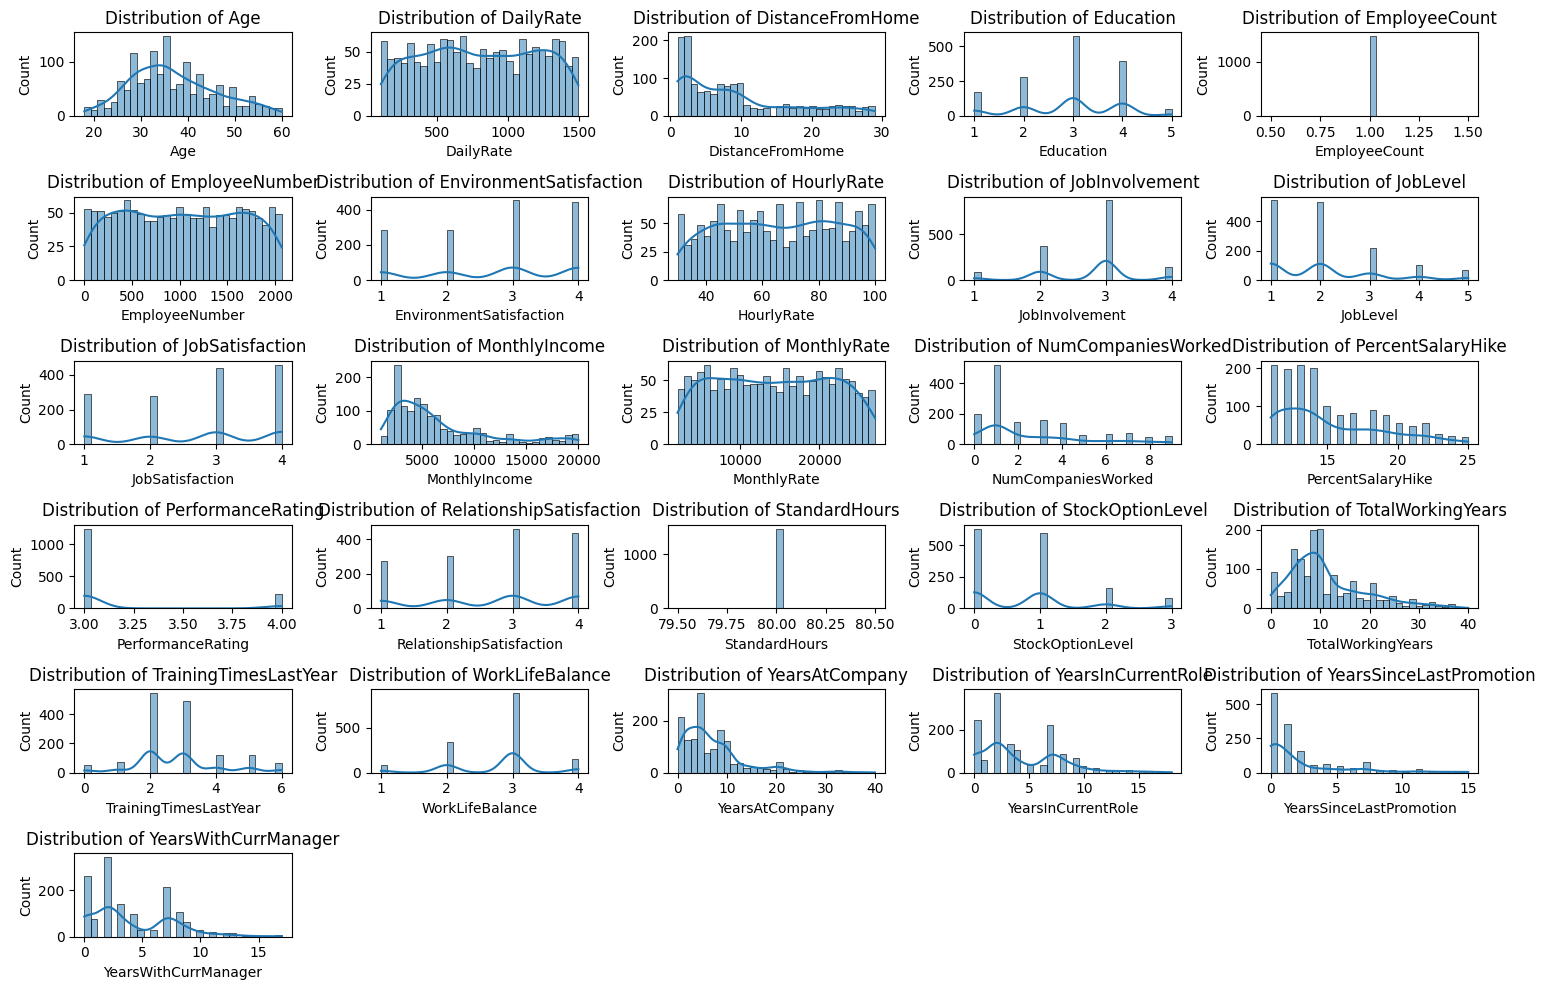

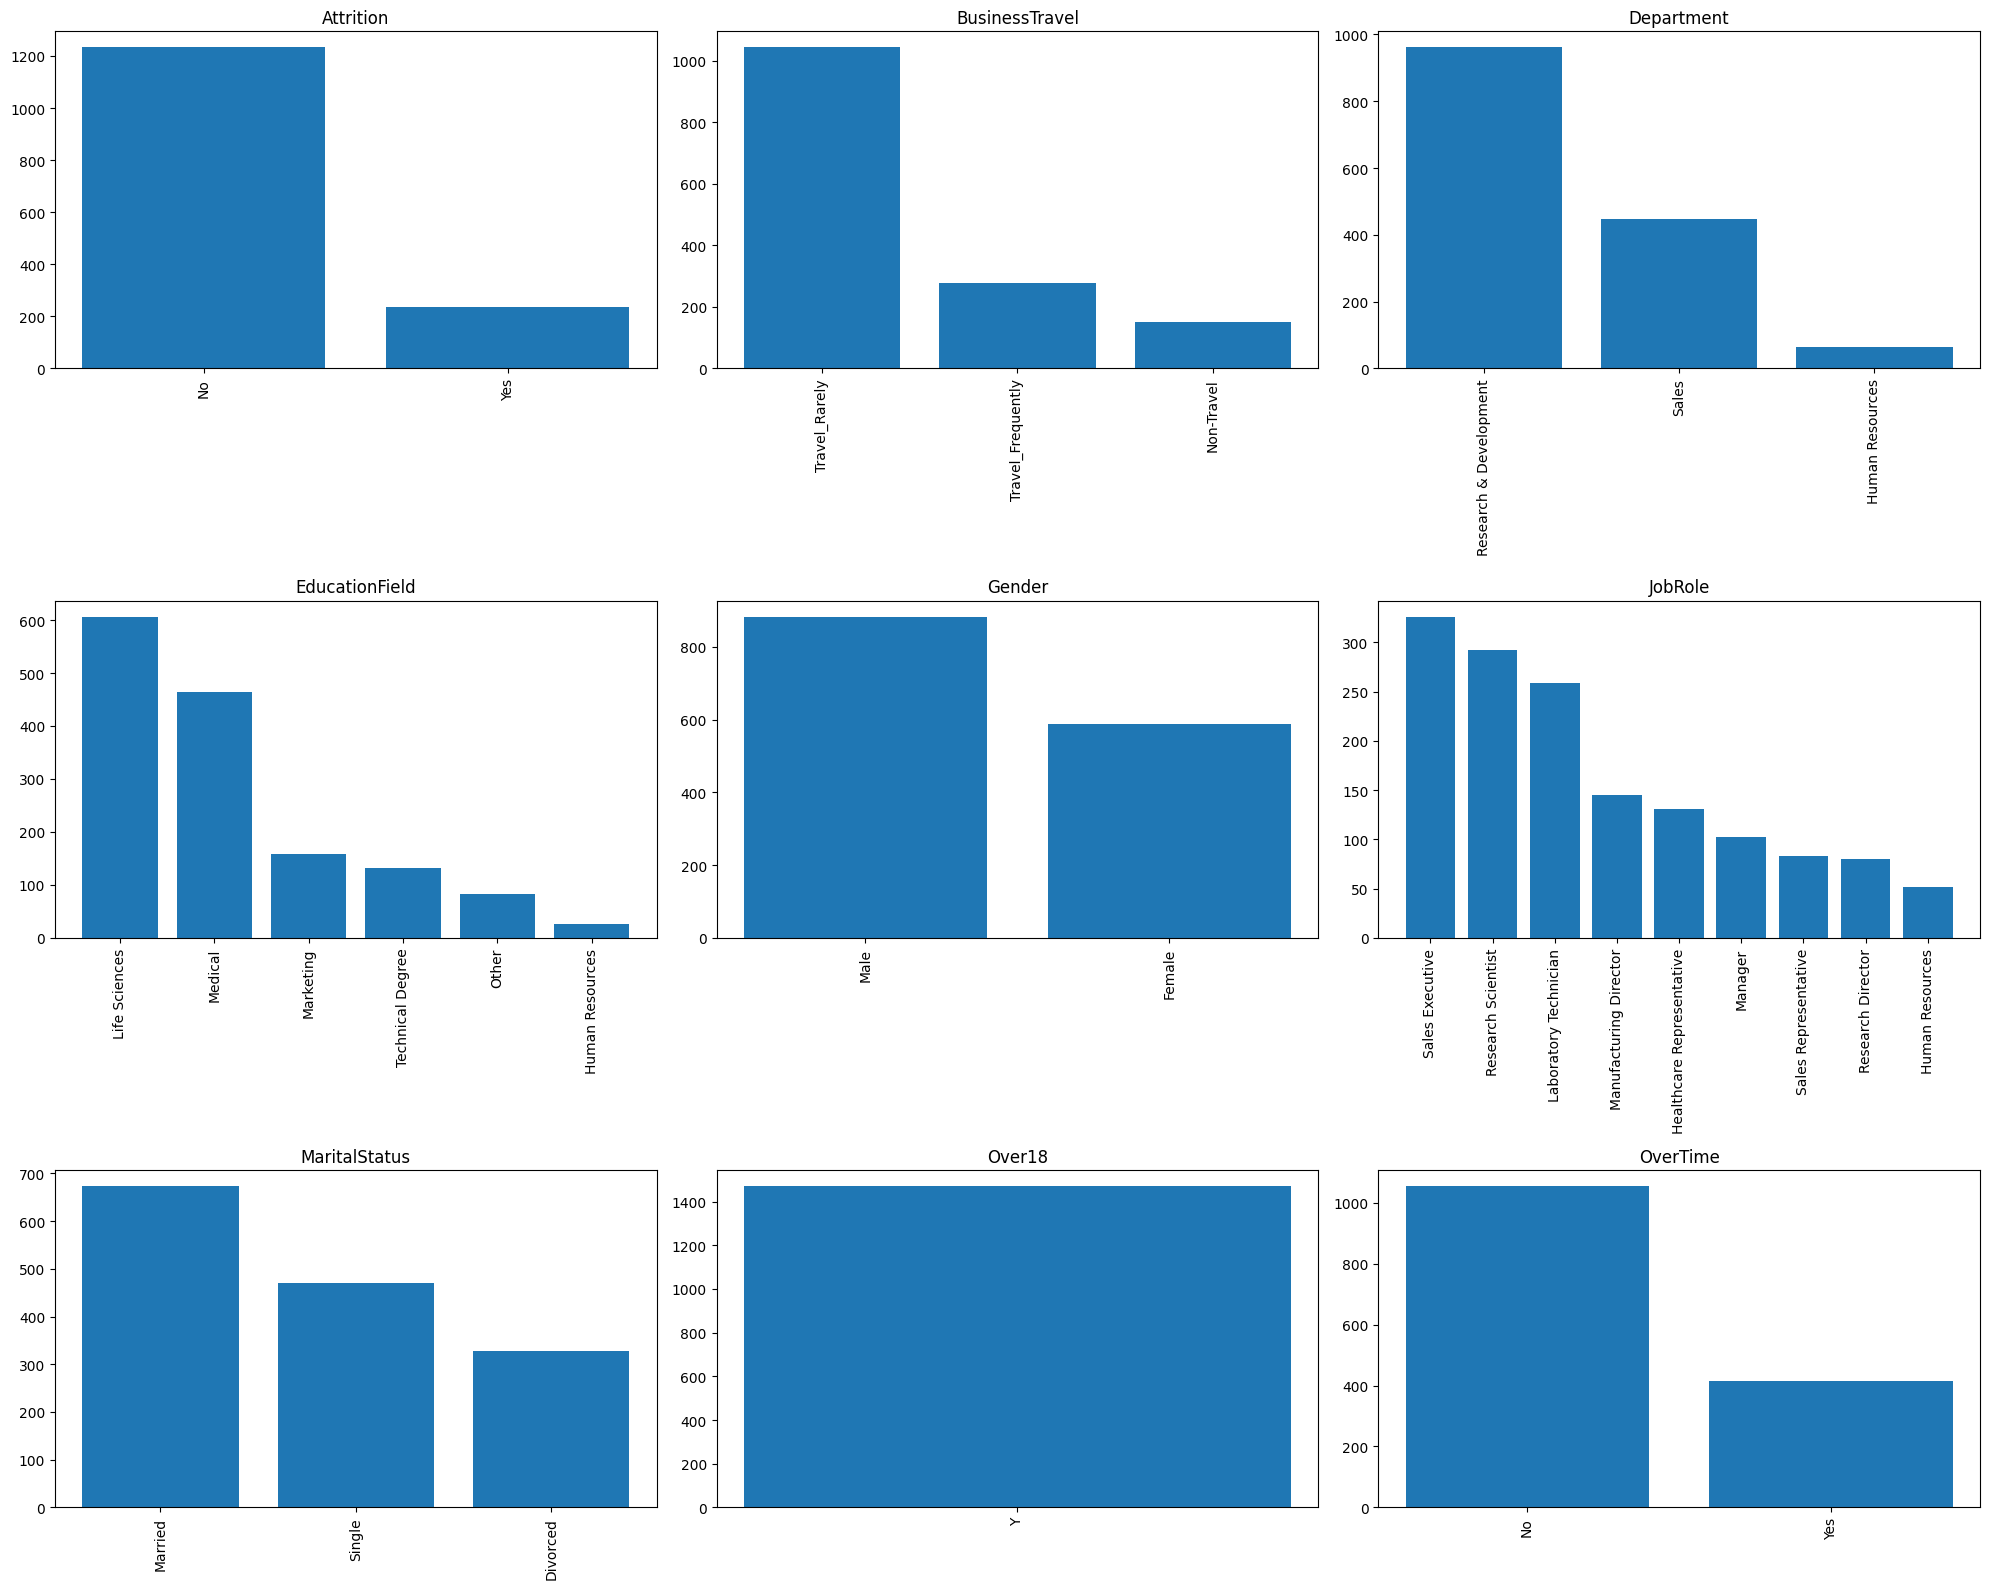

New DataFrame shape: (1470, 31)


In [4]:
# Check variable types
print(data.info())

# Split into categorical and numeric variables
cat_cols = data.select_dtypes(include=['object'])
num_cols = data.select_dtypes(include=['int64', 'float64'])

# Histograms of numeric variables
fig, axes = plt.subplots(6, 5, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.histplot(data=data, x=col, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

# Hide unused axes
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

print('='*100)

# Bar charts of categorical variables
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(cat_cols.columns):
    top10 = data[col].value_counts().head(10)
    axes[i].bar(top10.index, top10.values)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=90)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

print('='*100)
# After exploring the full dataset, drop the variables with no predictive value (constants and ID)
df = data.drop(columns=['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'])


# Shape of the new DataFrame:
print("New DataFrame shape:", df.shape)


Four variables are dropped:

- `EmployeeCount`, `StandardHours` and `Over18` are constant (1, 80 and "Y" in every record): they have no variability and cannot explain attrition.
- `EmployeeNumber` is a unique identifier unrelated to the decision to leave.

That leaves 30 input variables plus `Attrition` (the target).

## 4. Variable types and ethical considerations

| Type | Variables |
|---|---|
| Numeric (14) | NumCompaniesWorked, TrainingTimesLastYear, Age, DailyRate, DistanceFromHome, HourlyRate, MonthlyIncome, MonthlyRate, PercentSalaryHike, TotalWorkingYears, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager |
| Ordinal (9) | Education (5), EnvironmentSatisfaction (4), JobInvolvement (4), JobLevel (5), JobSatisfaction (4), PerformanceRating (2), RelationshipSatisfaction (4), StockOptionLevel (4), WorkLifeBalance (4) |
| Binary (3) | Attrition (target), Gender, OverTime |
| Nominal (5) | BusinessTravel (3), Department (3), EducationField (6), JobRole (9), MaritalStatus (3) |

**Sensitive variables.** Age, Gender and MaritalStatus are protected categories in most labor frameworks. A model that uses them can reproduce historical bias and expose the company to legal risk even when the decision is algorithmic. Dropping them is not enough, because other variables can act as proxies (for example, years of experience relative to age). That is why later sections measure how much performance is lost without them and audit recall by group.

## 5. Data split and target encoding

Stratified 70/15/15 split into Train, Validation and Test; the test set is used only once, at the end. `Attrition` is encoded with a `LabelEncoder` fit on Train only, to avoid data leakage (No = 0, Yes = 1).

In [5]:
print("Train / Validation / Test split sizes and percentages:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Input variables Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nTarget variable Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)


Train / Validation / Test split sizes and percentages:
---------------------------------------------------------------------------
Input variables Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Target variable Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


In [6]:
le = LabelEncoder()
le.fit(ytrain['Attrition'])  # fit on train only

# Transform and rebuild as DataFrames with the 'Attrition' column
ytrainT = ytrain.copy()
ytrainT['Attrition'] = le.transform(ytrain['Attrition'])

yvalT = yval.copy()
yvalT['Attrition'] = le.transform(yval['Attrition'])

ytestT = ytest.copy()
ytestT['Attrition'] = le.transform(ytest['Attrition'])


print('Class proportions in the training set (Train):\n', ytrainT['Attrition'].value_counts() / ytrainT.shape[0])


Class proportions in the training set (Train):
 Attrition
0    0.838678
1    0.161322
Name: count, dtype: float64


**Imbalance and baseline.** Only 16.1% of employees leave. A model that always predicts "No" already scores 83.9% (the baseline), and any model has to beat it. Even so, accuracy is misleading: it can be high without catching anyone who leaves. That is why precision, recall, F1, ROC-AUC and PR-AUC are reported too, along with the confusion matrix.

## 6. Exploratory analysis (Train only)

The analysis that drives the transformations uses the training set only: distributions, skewness, outliers, correlations and attrition rates by category.

<class 'pandas.core.frame.DataFrame'>
Index: 1029 entries, 565 to 308
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1029 non-null   int64 
 1   BusinessTravel            1029 non-null   object
 2   DailyRate                 1029 non-null   int64 
 3   Department                1029 non-null   object
 4   DistanceFromHome          1029 non-null   int64 
 5   Education                 1029 non-null   int64 
 6   EducationField            1029 non-null   object
 7   EnvironmentSatisfaction   1029 non-null   int64 
 8   Gender                    1029 non-null   object
 9   HourlyRate                1029 non-null   int64 
 10  JobInvolvement            1029 non-null   int64 
 11  JobLevel                  1029 non-null   int64 
 12  JobRole                   1029 non-null   object
 13  JobSatisfaction           1029 non-null   int64 
 14  MaritalStatus             10

,dtype,unique_values,%_most_frequent
PerformanceRating,int64,2,85.811467
EnvironmentSatisfaction,int64,4,30.903790
JobInvolvement,int64,4,59.863946
JobSatisfaction,int64,4,32.264334
RelationshipSatisfaction,int64,4,31.292517
StockOptionLevel,int64,4,42.274052
WorkLifeBalance,int64,4,62.001944
Education,int64,5,38.678328
JobLevel,int64,5,36.929057
TrainingTimesLastYear,int64,7,37.026239


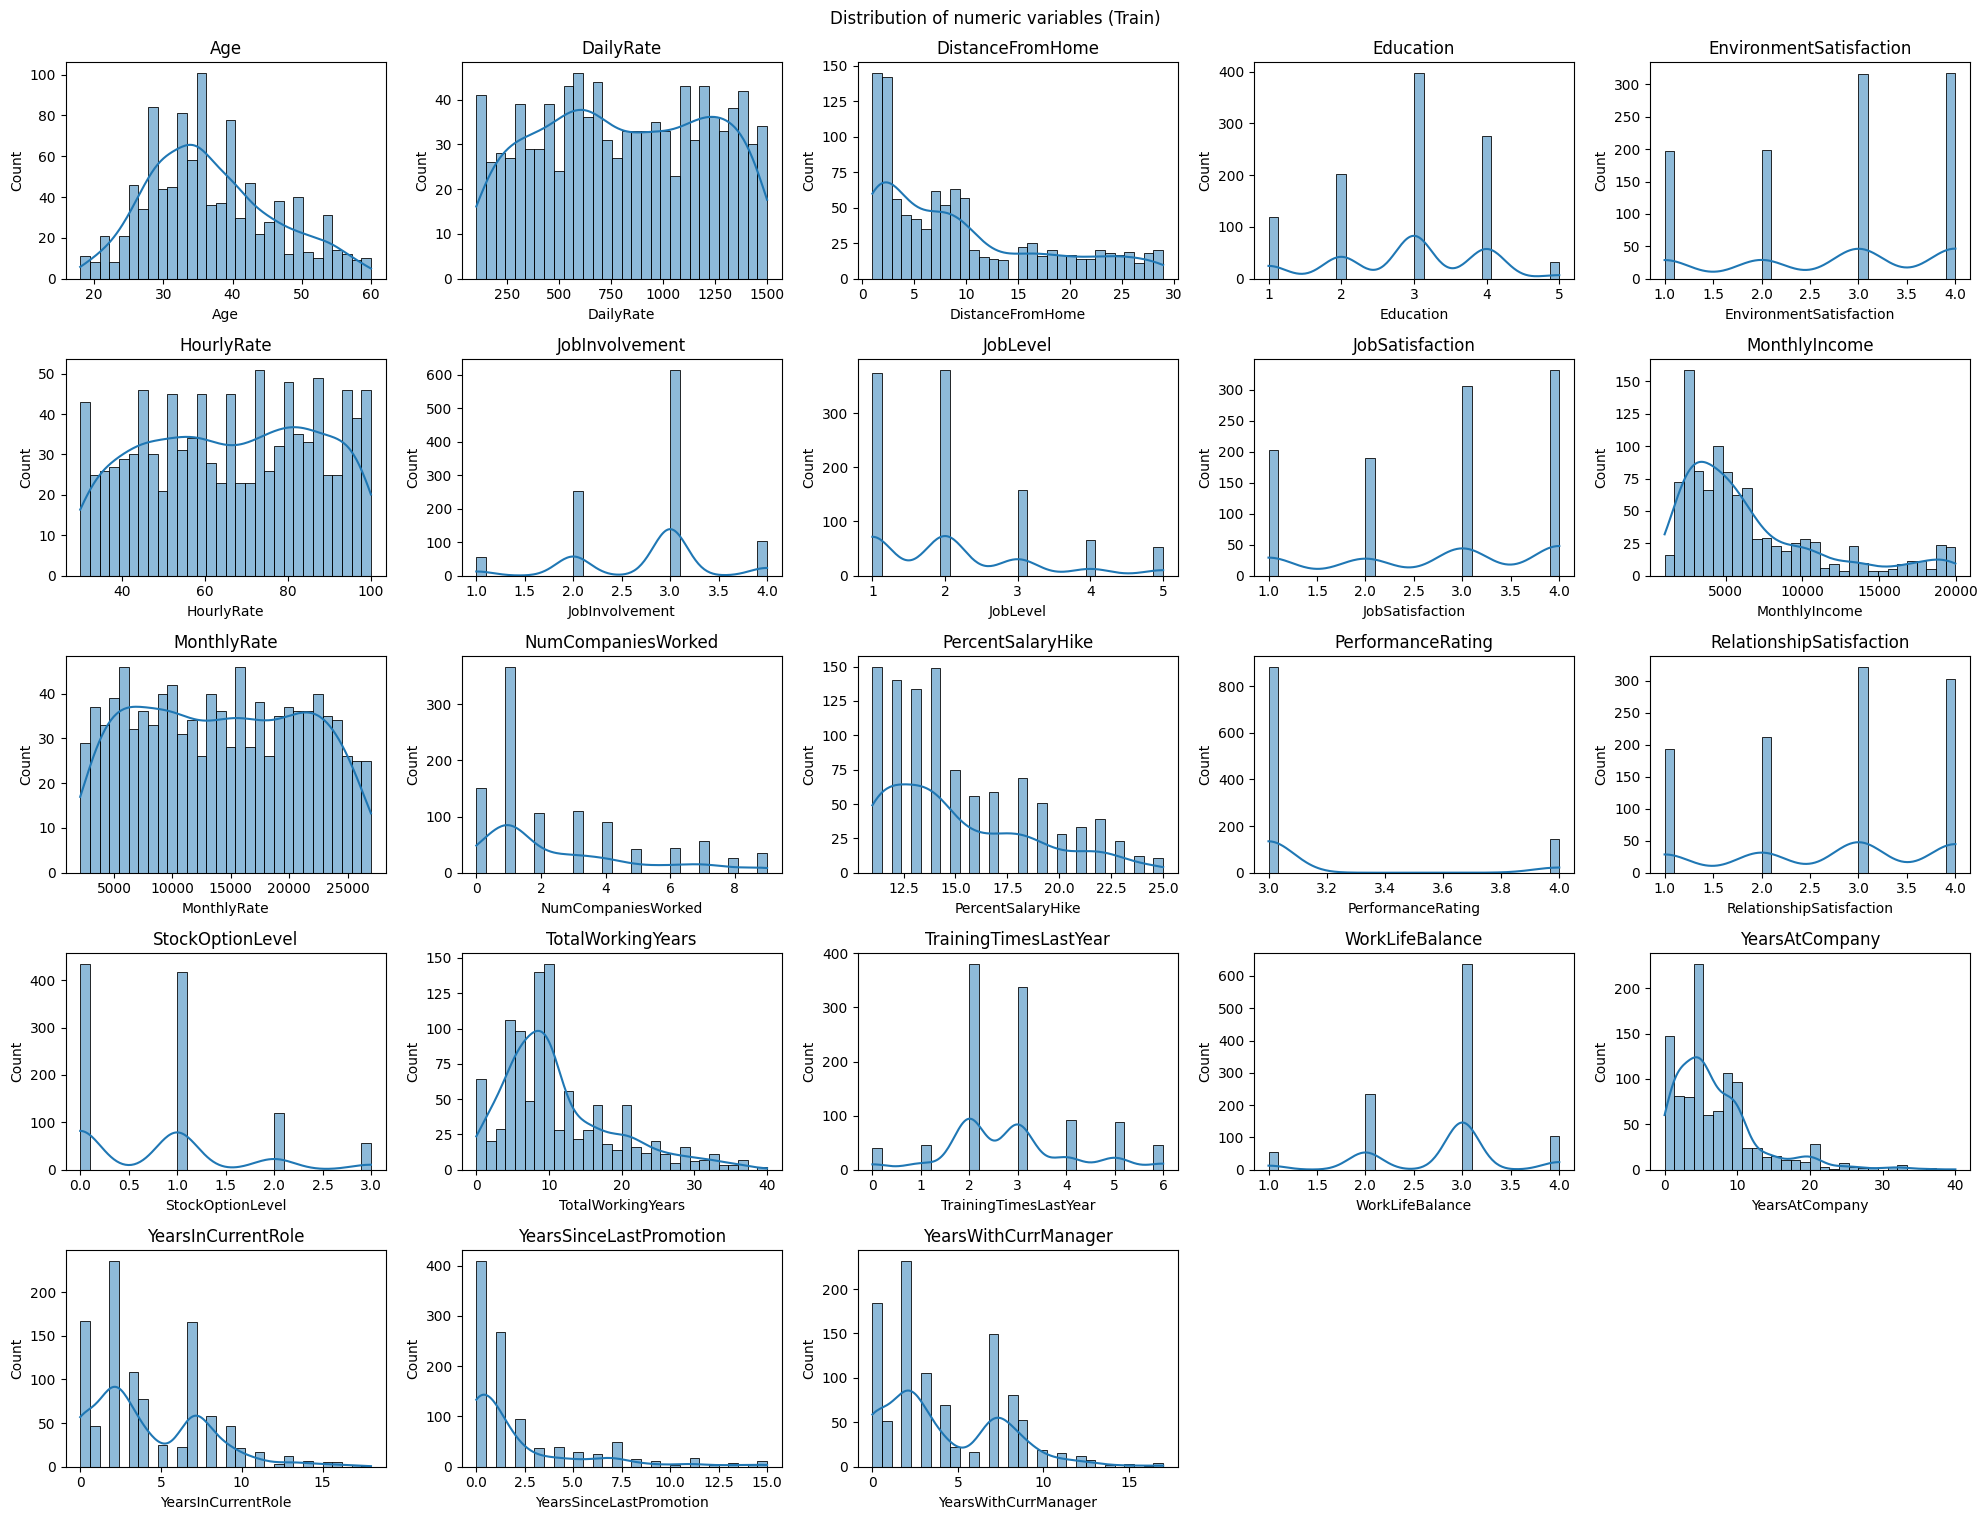

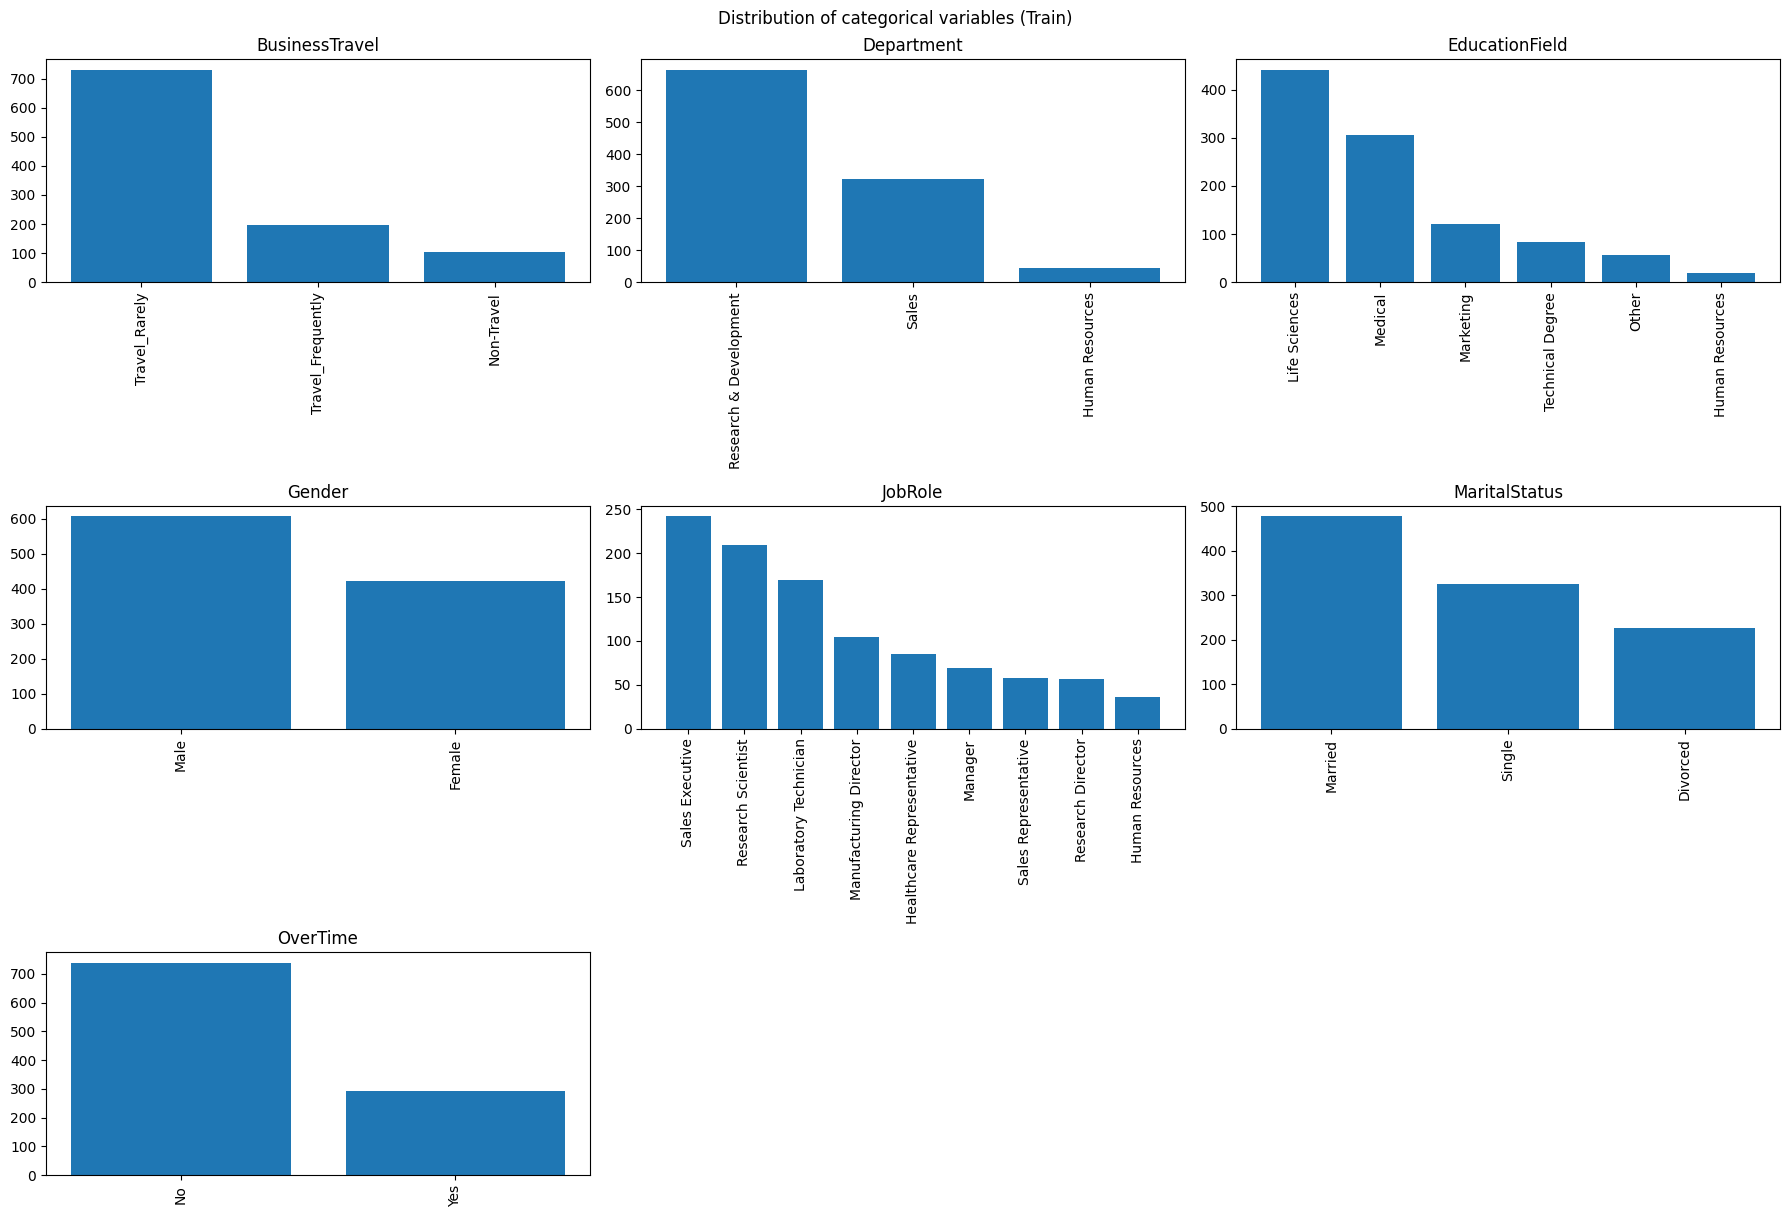

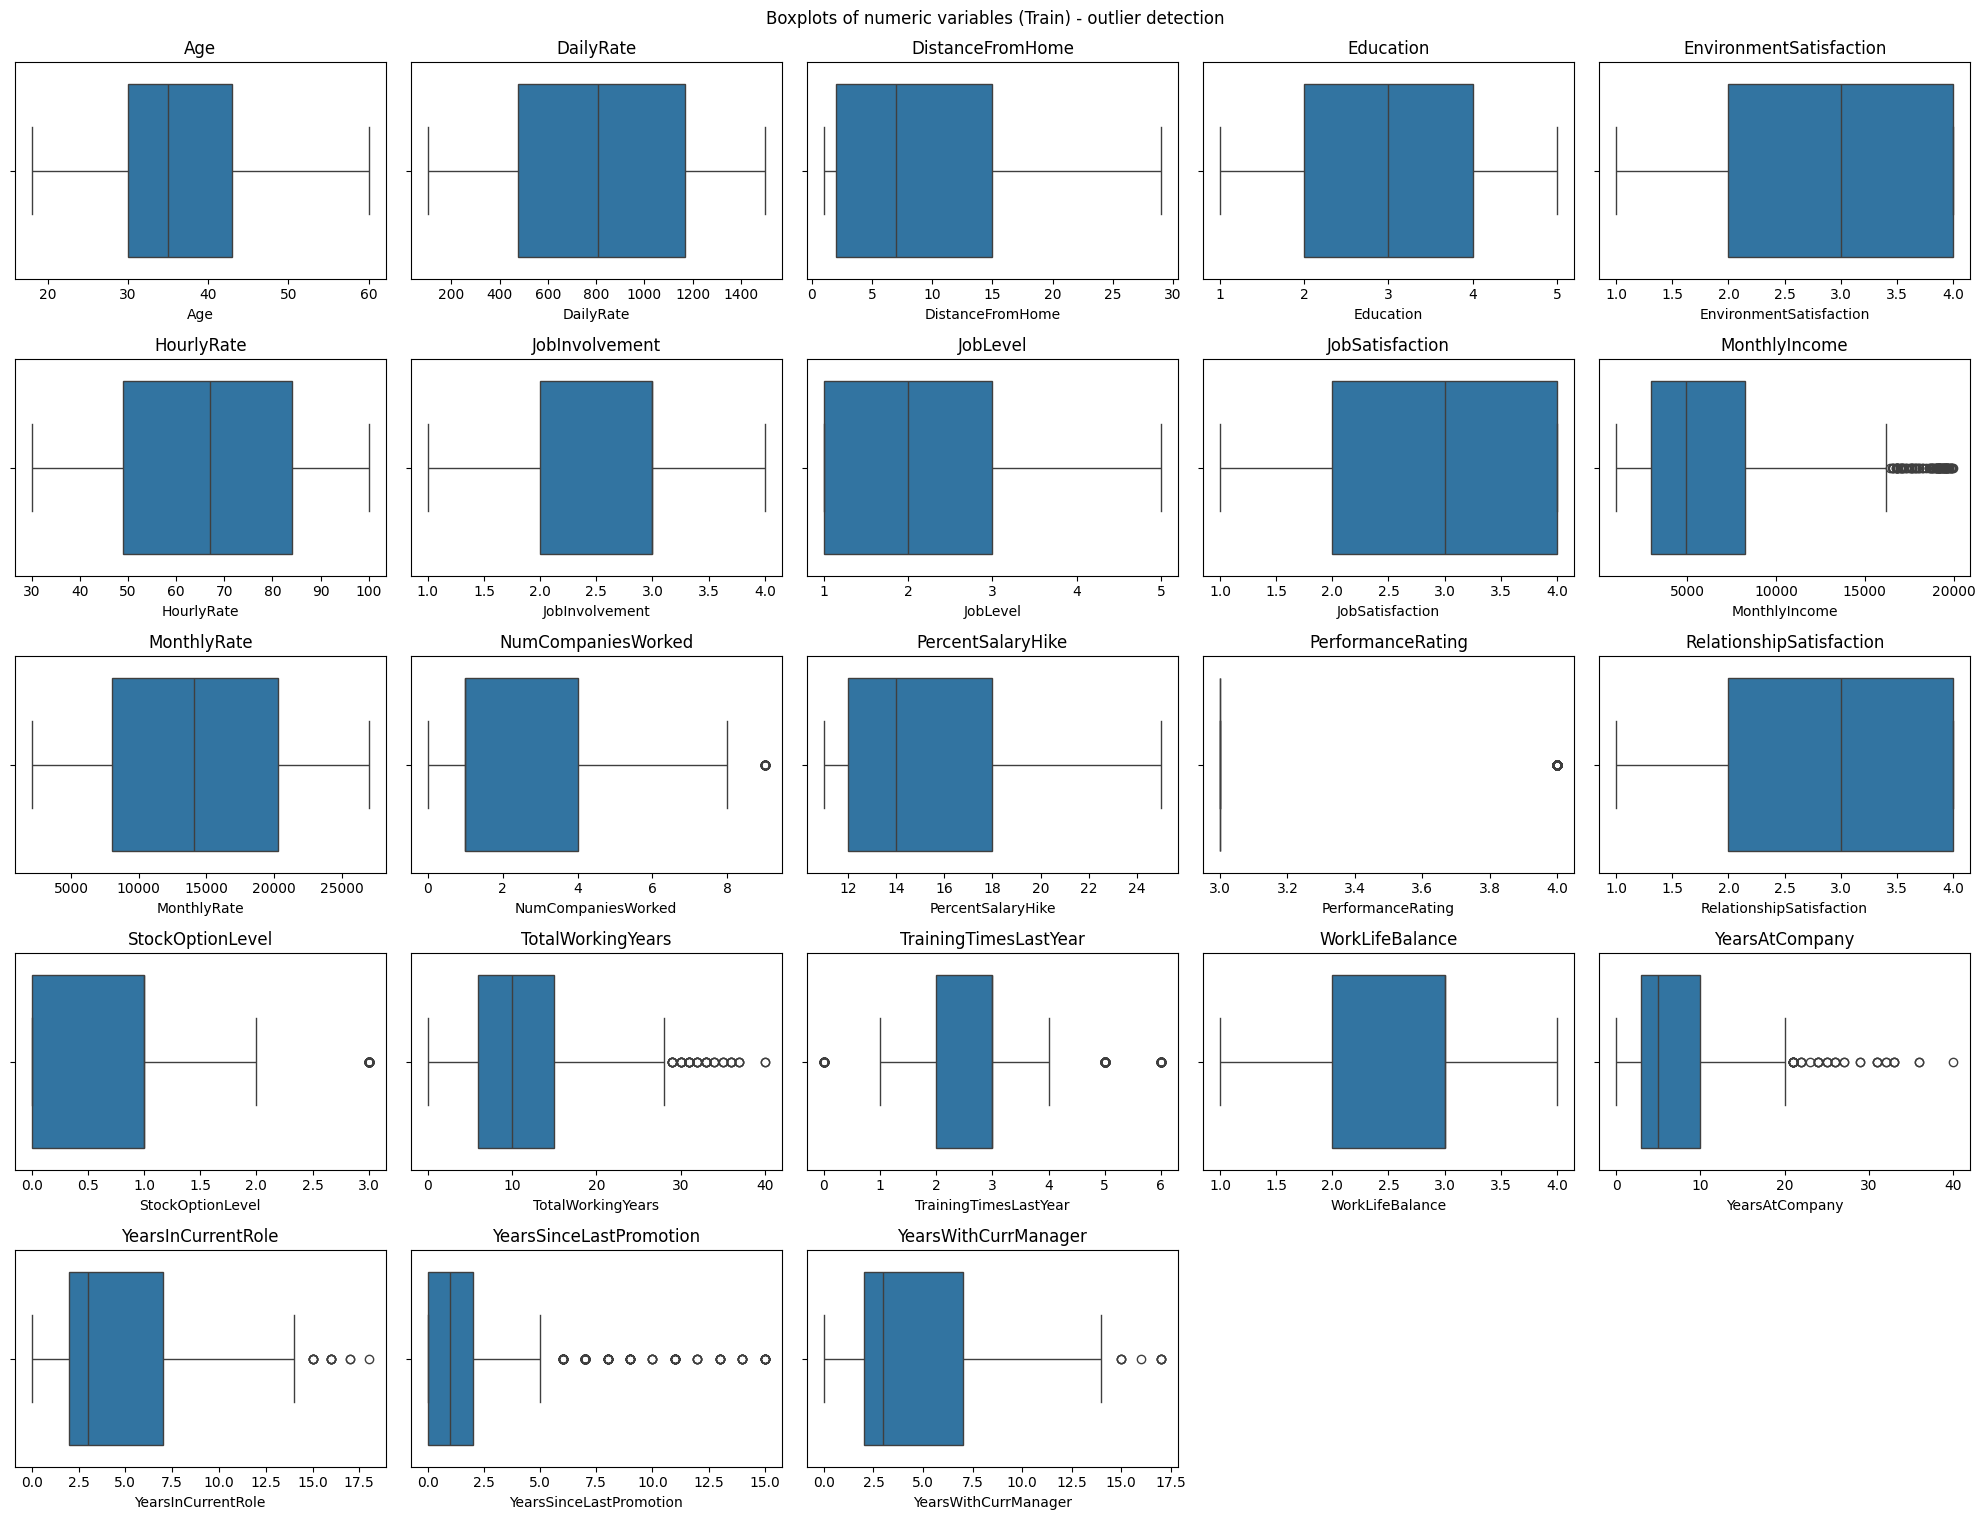


Descriptive statistics of numeric variables:


,count,mean,std,min,25%,50%,75%,max
Age,1029.0,36.839650,9.096571,18.0,30.0,35.0,43.0,60.0
DailyRate,1029.0,811.583090,401.584530,102.0,474.0,809.0,1169.0,1499.0
DistanceFromHome,1029.0,9.491740,8.246753,1.0,2.0,7.0,15.0,29.0
Education,1029.0,2.903790,1.023781,1.0,2.0,3.0,4.0,5.0
EnvironmentSatisfaction,1029.0,2.733722,1.094308,1.0,2.0,3.0,4.0,4.0
HourlyRate,1029.0,66.236152,20.408084,30.0,49.0,67.0,84.0,100.0
JobInvolvement,1029.0,2.744412,0.706956,1.0,2.0,3.0,3.0,4.0
JobLevel,1029.0,2.071914,1.108281,1.0,1.0,2.0,3.0,5.0
JobSatisfaction,1029.0,2.745384,1.108549,1.0,2.0,3.0,4.0,4.0
MonthlyIncome,1029.0,6519.171040,4695.767631,1009.0,2974.0,4969.0,8268.0,19973.0



Skewness of numeric variables:
PerformanceRating           2.055628
YearsSinceLastPromotion     2.039782
YearsAtCompany              1.813217
MonthlyIncome               1.394044
TotalWorkingYears           1.157577
NumCompaniesWorked          1.080789
JobLevel                    1.047628
StockOptionLevel            0.924751
DistanceFromHome            0.889646
YearsInCurrentRole          0.868755
PercentSalaryHike           0.835244
YearsWithCurrManager        0.750367
TrainingTimesLastYear       0.510386
Age                         0.426284
MonthlyRate                 0.039405
DailyRate                  -0.019677
HourlyRate                 -0.067444
Education                  -0.275299
RelationshipSatisfaction   -0.303544
EnvironmentSatisfaction    -0.337055
JobSatisfaction            -0.352045
JobInvolvement             -0.518246
WorkLifeBalance            -0.594951
dtype: float64


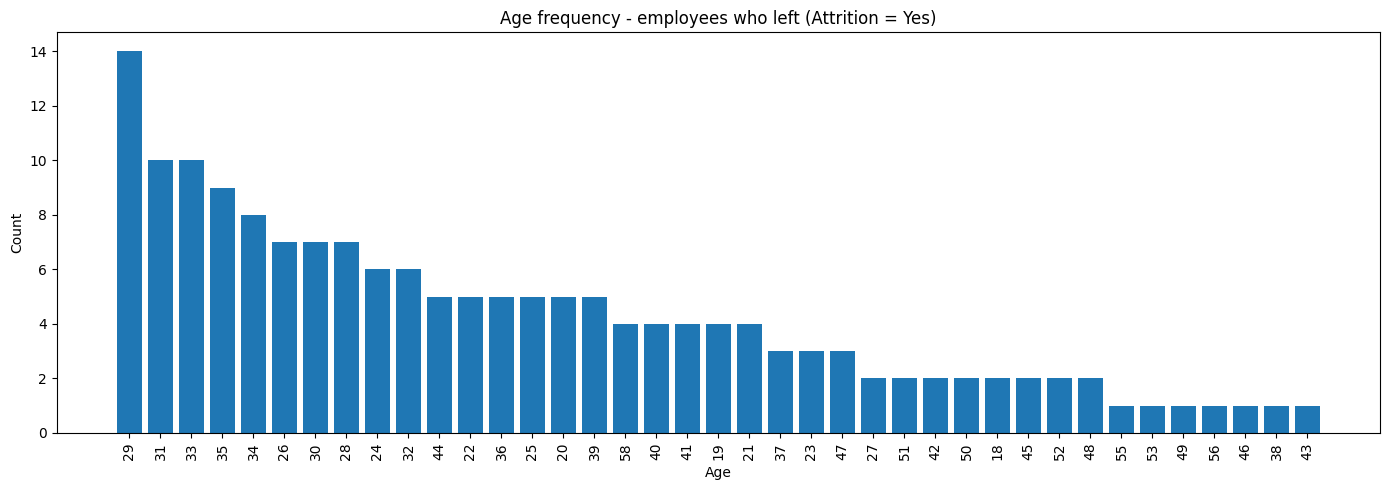

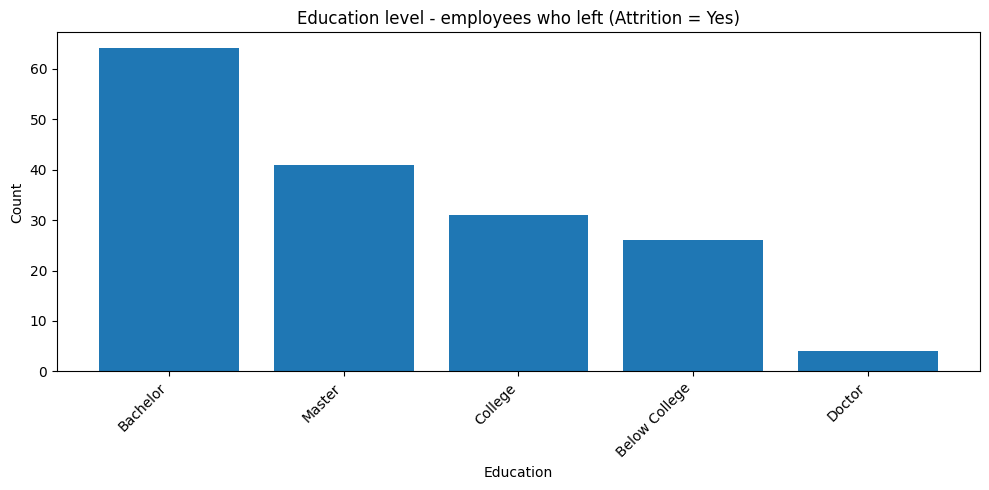

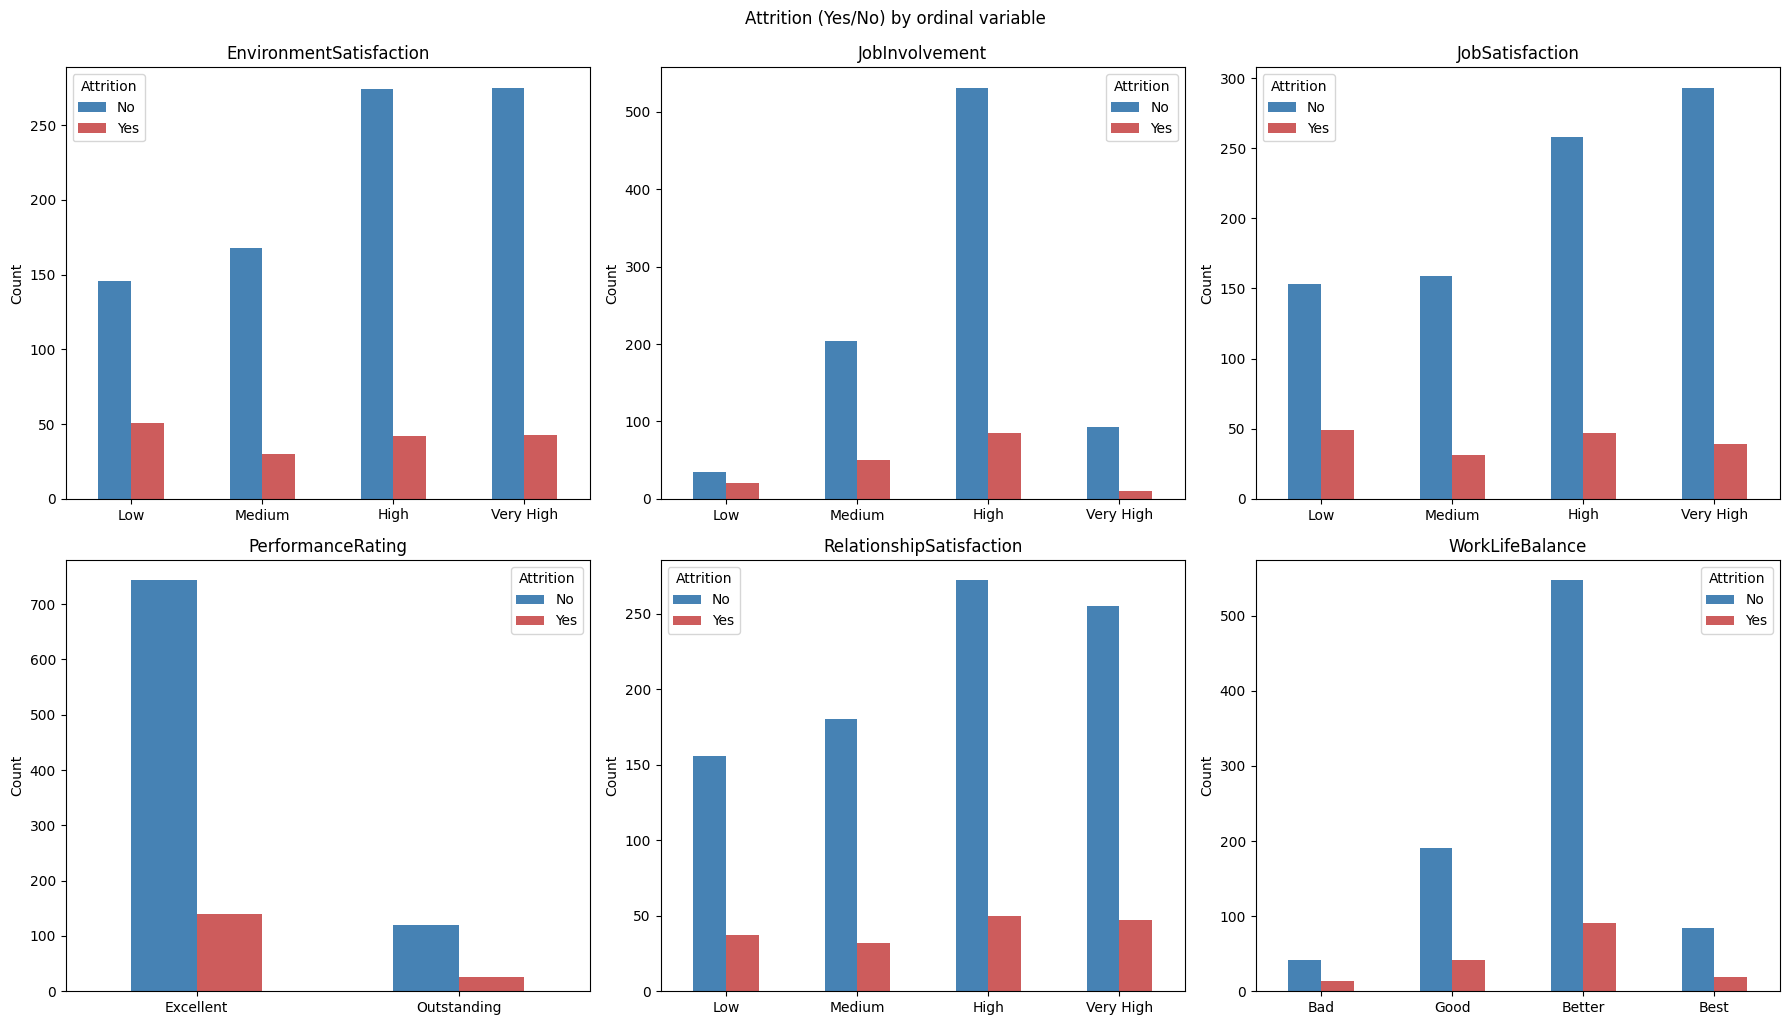

In [7]:
# Analysis and plots

# 1. Overview: variable types and unique values
print(Xtrain.info())
print('='*100)

print("\nUnique values per column:")
summary = pd.DataFrame({
    'dtype': Xtrain.dtypes,
    'unique_values': Xtrain.nunique(),
    '%_most_frequent': [Xtrain[col].value_counts(normalize=True).max()*100 for col in Xtrain.columns]
})
display(summary.sort_values(['dtype','unique_values']))
print('='*100)

# 2. Split numeric and categorical
num_cols = Xtrain.select_dtypes(include=['int64', 'float64'])
cat_cols = Xtrain.select_dtypes(include=['object'])

# 3. Histograms of numeric variables - to see skew and scale
n = len(num_cols.columns)
ncols = 5
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*3))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.histplot(data=Xtrain, x=col, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'{col}')

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Distribution of numeric variables (Train)', y=1.01)
plt.show()

# 4. Bar charts of categorical variables - to see category balance
n_cat = len(cat_cols.columns)
ncols_cat = 3
nrows_cat = math.ceil(n_cat / ncols_cat)
fig, axes = plt.subplots(nrows_cat, ncols_cat, figsize=(18, nrows_cat*4))
axes = axes.flatten()

for i, col in enumerate(cat_cols.columns):
    counts = Xtrain[col].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=90)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Distribution of categorical variables (Train)', y=1.01)
plt.show()

# 5. Boxplots of numeric variables - to spot outliers
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows*3))
axes = axes.flatten()

for i, col in enumerate(num_cols.columns):
    sns.boxplot(data=Xtrain, x=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Boxplots of numeric variables (Train) - outlier detection', y=1.01)
plt.show()

# 6. Descriptive statistics
print("\nDescriptive statistics of numeric variables:")
display(num_cols.describe().T)

# 7. Skewness of each numeric variable - to decide on Yeo-Johnson
print("\nSkewness of numeric variables:")
skewness = num_cols.skew().sort_values(ascending=False)
print(skewness)

print('='*100)

# Age of employees who left
# Temporarily join Xtrain with the encoded target, only to filter by Attrition in this exploratory analysis
df_temp = Xtrain.copy()
df_temp['Attrition'] = ytrainT.values

# Keep only employees who left (Attrition = 1, "Yes")
ages_attrition_yes = df_temp[df_temp['Attrition'] == 1]['Age']

# Count by age and sort from most to least frequent
counts_by_age = ages_attrition_yes.value_counts().sort_values(ascending=False)

# Plot
plt.figure(figsize=(14, 5))
plt.bar(counts_by_age.index.astype(str), counts_by_age.values)
plt.title('Age frequency - employees who left (Attrition = Yes)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print('='*100)

# Education level of employees who left

# Label mapping, as documented on Kaggle
education_map = {
    1: 'Below College',
    2: 'College',
    3: 'Bachelor',
    4: 'Master',
    5: 'Doctor'
}

# Reuse df_temp (Xtrain + Attrition already joined)
# Keep only employees who left
education_attrition_yes = df_temp[df_temp['Attrition'] == 1]['Education']

# Count and sort from most to least frequent
counts_by_education = education_attrition_yes.value_counts().sort_values(ascending=False)

# Replace the numbers with the Kaggle labels, keeping the order
labels = [education_map[val] for val in counts_by_education.index]

# Plot
plt.figure(figsize=(10, 5))
plt.bar(labels, counts_by_education.values)
plt.title('Education level - employees who left (Attrition = Yes)')
plt.xlabel('Education')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print('='*100)

# Attrition by ordinal variable
label_maps = {
    'EnvironmentSatisfaction': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'JobInvolvement': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'JobSatisfaction': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'PerformanceRating': {1: 'Low', 2: 'Good', 3: 'Excellent', 4: 'Outstanding'},
    'RelationshipSatisfaction': {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'},
    'WorkLifeBalance': {1: 'Bad', 2: 'Good', 3: 'Better', 4: 'Best'}
}

variables = list(label_maps.keys())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, var in enumerate(variables):
    # Count table: rows = variable levels, columns = Attrition (0/1)
    table = pd.crosstab(df_temp[var], df_temp['Attrition'])

    # Replace the numeric index with the matching labels
    table.index = [label_maps[var][val] for val in table.index]

    # Rename columns so the legend is clear
    table = table.rename(columns={0: 'No', 1: 'Yes'})

    table.plot(kind='bar', ax=axes[i], color=['steelblue', 'indianred'])
    axes[i].set_title(var)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(title='Attrition')

plt.tight_layout()
plt.suptitle('Attrition (Yes/No) by ordinal variable', y=1.02)
plt.show()


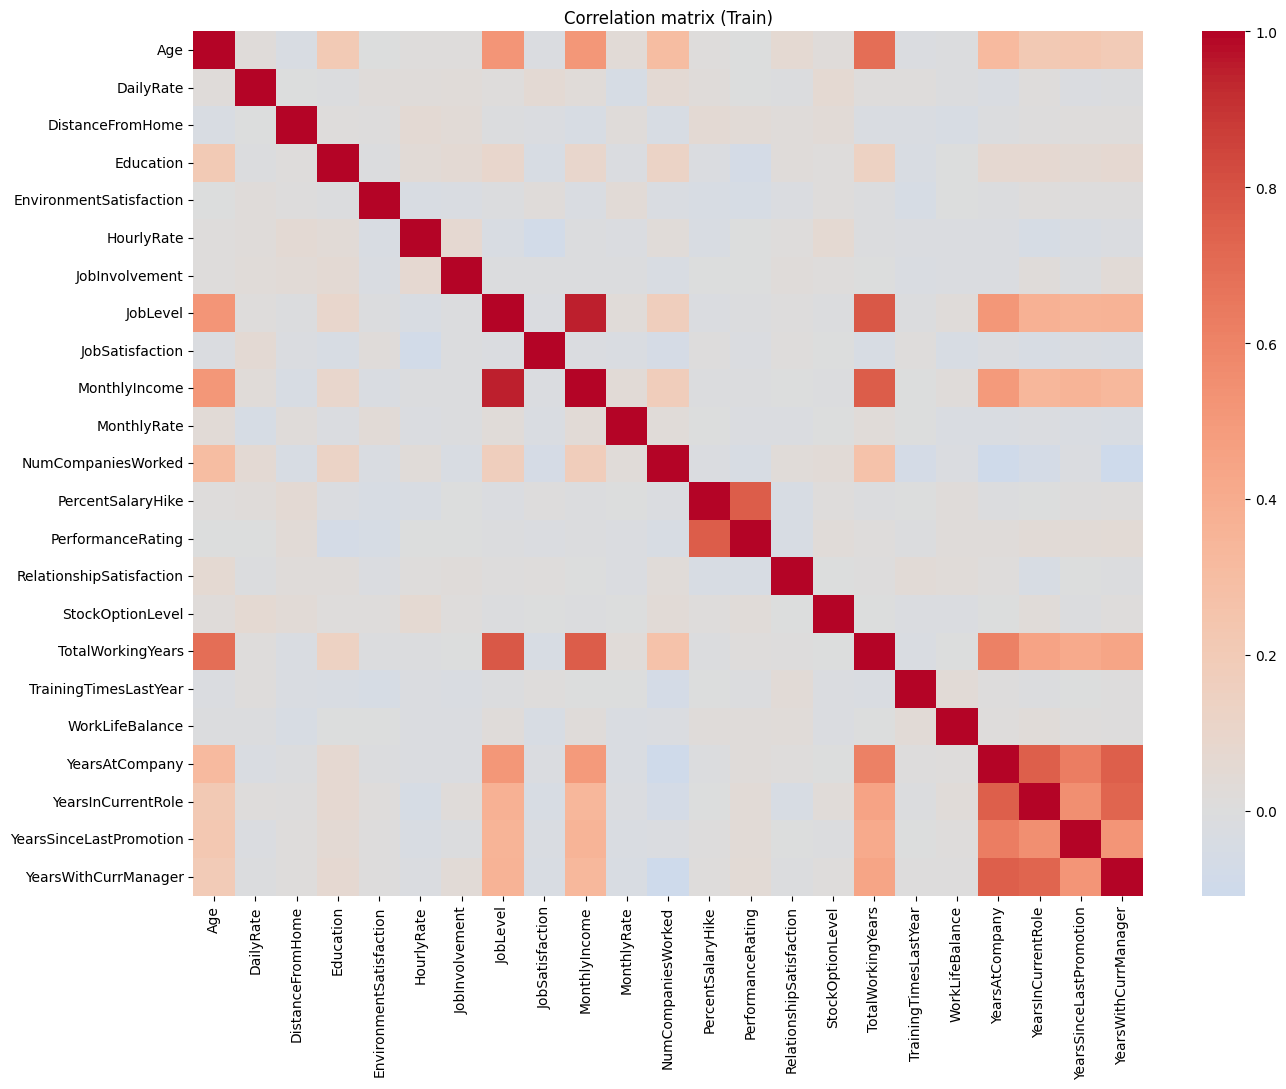

Pairs with |r| > 0.7:


,var1,var2,r
134,JobLevel,MonthlyIncome,0.950029
141,JobLevel,TotalWorkingYears,0.770934
168,MonthlyIncome,TotalWorkingYears,0.764900
198,PercentSalaryHike,PerformanceRating,0.764425
249,YearsAtCompany,YearsWithCurrManager,0.756956
247,YearsAtCompany,YearsInCurrentRole,0.755669
251,YearsInCurrentRole,YearsWithCurrManager,0.730480



VIF (values > 5 suggest relevant multicollinearity):


,VIF
JobLevel,11.148553
MonthlyIncome,10.945099
TotalWorkingYears,4.565745
YearsAtCompany,4.280327
YearsInCurrentRole,2.802285
YearsWithCurrManager,2.768123
PerformanceRating,2.458351
PercentSalaryHike,2.444700
Age,2.072269
YearsSinceLastPromotion,1.704996



Attrition rate by OverTime:


,attrition_rate,n
OverTime,,
Yes,0.323,291
No,0.098,738


... (4 outputs left out)


Attrition rate by Department:


,attrition_rate,n
Department,,
Sales,0.217,322
Human Resources,0.209,43
Research & Development,0.131,664



Attrition rate by JobRole:


,attrition_rate,n
JobRole,,
Sales Representative,0.448,58
Human Resources,0.250,36
Laboratory Technician,0.213,169
Sales Executive,0.174,242
Research Scientist,0.163,209
Manufacturing Director,0.077,104
Healthcare Representative,0.071,85
Manager,0.058,69
Research Director,0.018,57


In [8]:
# Relationships between variables and multicollinearity (Train only)
num_ord = Xtrain.select_dtypes(include=['int64', 'float64'])

# 1. Correlation matrix
corr = num_ord.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation matrix (Train)')
plt.tight_layout()
plt.show()

# 2. Highly correlated pairs (|r| > 0.7)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ['var1', 'var2', 'r']
print("Pairs with |r| > 0.7:")
display(pairs[pairs['r'].abs() > 0.7].sort_values('r', key=lambda s: s.abs(), ascending=False))

# 3. Variance inflation factor (VIF), computed from the inverse correlation matrix
Z = (num_ord - num_ord.mean()) / num_ord.std()
vif = pd.Series(np.diag(np.linalg.pinv(np.corrcoef(Z.values, rowvar=False))),
                index=num_ord.columns, name='VIF').sort_values(ascending=False)
print("\nVIF (values > 5 suggest relevant multicollinearity):")
display(vif.to_frame().head(10))

# 4. Attrition rate by category (Train)
df_rate = Xtrain.copy()
df_rate['Attrition'] = ytrainT['Attrition']
for col in ['OverTime', 'BusinessTravel', 'MaritalStatus', 'Department', 'JobRole']:
    print(f"\nAttrition rate by {col}:")
    display(df_rate.groupby(col)['Attrition'].agg(attrition_rate='mean', n='count')
            .sort_values('attrition_rate', ascending=False).round(3))


**Findings that guide the modeling**

- Several numeric variables are strongly right-skewed (for example `YearsSinceLastPromotion` 2.04, `YearsAtCompany` 1.81 and `MonthlyIncome` 1.39), which justifies a Yeo-Johnson transform.
- Multicollinearity is strong: `JobLevel` and `MonthlyIncome` have r = 0.95 and a VIF near 11, and `YearsAtCompany`, `YearsInCurrentRole` and `YearsWithCurrManager` correlate with each other (r between 0.73 and 0.76). This makes individual coefficients unstable.
- Attrition rates in Train differ sharply by category: 32% with overtime versus 10% without; 27% among single employees versus 9% among divorced; 45% among Sales Representatives versus 2% among Research Directors.
- A false negative (losing someone with no intervention) costs more than a false positive (an unneeded retention conversation), so recall should be prioritized.

## 7. Preprocessing

A `ColumnTransformer` applies a transformation to each variable type inside a `Pipeline`, so everything is refit in every cross-validation fold (no data leakage):

| Type | Transformation |
|---|---|
| Numeric (14) | median + Yeo-Johnson + standardization |
| Ordinal (9) | mode + standardization |
| Binary (2) | mode + ordinal encoding |
| Nominal (5) | mode + one-hot (`drop='first'`) |

Train and Validation are merged into one set (`Xtv`, `ytv`) because cross-validation is used.

In [9]:
# NUMERIC: median imputation + skew correction (Yeo-Johnson, which already standardizes)
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('yeojohnson', PowerTransformer(method='yeo-johnson', standardize=True))])
numeric_cols = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate',
                              'NumCompaniesWorked', 'PercentSalaryHike','TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany',
                              'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

# ORDINAL: mode imputation (discrete ordered categories); already numeric with a real order, so they are only scaled
ordinal_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('scaler', StandardScaler())])
ordinal_cols = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel','JobSatisfaction',
                           'PerformanceRating', 'RelationshipSatisfaction','WorkLifeBalance', 'StockOptionLevel']

# BINARY: mode imputation + ordinal encoding
binary_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder())])
binary_cols = ['Gender', 'OverTime']

# NOMINAL: mode imputation + one-hot encoding (no order between categories)
nominal_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])
nominal_cols = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']


preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_cols),
    ('ord', ordinal_pipeline, ordinal_cols),
    ('bin', binary_pipeline, binary_cols),
    ('nom', nominal_pipeline, nominal_cols)
])


In [10]:
Xtv = pd.concat([Xtrain, Xval], axis=0)
ytv = pd.concat([ytrainT, yvalT], axis=0)


print("Train+Val shape:")
print(Xtv.shape)
print(ytv.shape)


Train+Val shape:
(1249, 30)
(1249, 1)


## 8. Model comparison and hyperparameter tuning

Logistic regression without penalty, Lasso (L1), Ridge (L2), ElasticNet and KNN are compared with `GridSearchCV` (5 folds × 3 repeats, accuracy metric). The selected models are re-evaluated on different splits (another seed) to reduce selection optimism. All use `random_state=1`.

>> LR  acc=0.885 (0.018)  params={}
>> LASSO  acc=0.889 (0.017)  params={'C': 0.3}
>> RIDGE  acc=0.889 (0.020)  params={'C': 0.3}
>> EN  acc=0.889 (0.020)  params={'C': 1, 'l1_ratio': 0.3}
>> KNN  acc=0.849 (0.009)  params={'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}

Naive-model accuracy on Train+Val: 0.8391


,best_hyperparameters,acc_search,acc_eval_mean,acc_eval_std,gain_vs_baseline_pp
model,,,,,
LR,{},0.8855,0.8852,0.0179,4.6174
LASSO,{'C': 0.3},0.8898,0.8887,0.0171,4.9641
RIDGE,{'C': 0.3},0.8895,0.8887,0.0198,4.9648
EN,"{'C': 1, 'l1_ratio': 0.3}",0.8892,0.8887,0.0196,4.9644
KNN,"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}",0.8511,0.8487,0.0093,0.9614


Spread across logistic variants: 0.0035 | max std: 0.0198 -> differences within noise
LR: BEATS the baseline by 4.62 percentage points
LASSO: BEATS the baseline by 4.96 percentage points
RIDGE: BEATS the baseline by 4.96 percentage points
EN: BEATS the baseline by 4.96 percentage points
KNN: BEATS the baseline by 0.96 percentage points


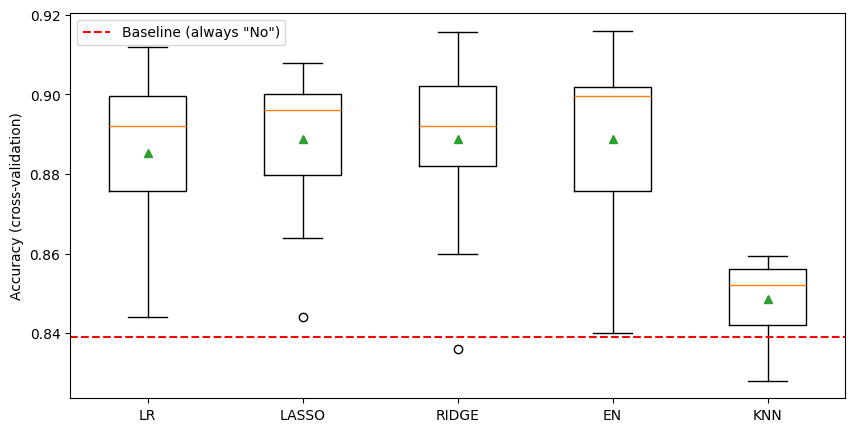

In [11]:
# Hyperparameter tuning.
#     Preprocessing lives INSIDE the Pipeline: it is refit in every fold of the cross-
#     validation, so there is no data leakage. random_state=1 is used in every model.

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

y_tv = np.ravel(ytv)
baseline_tv = 1 - y_tv.mean()      # naive-model accuracy (always "No") on Train+Val

candidates = {
    'LR':    (LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000, random_state=1), {}),
    'LASSO': (LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=1),
              {'m__C': [0.03, 0.1, 0.3, 1, 3, 10]}),
    'RIDGE': (LogisticRegression(penalty='l2', solver='liblinear', max_iter=1000, random_state=1),
              {'m__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]}),
    'EN':    (LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000, random_state=1),
              {'m__C': [0.1, 0.3, 1, 3], 'm__l1_ratio': [0.3, 0.5, 0.7]}),
    'KNN':   (KNeighborsClassifier(),
              {'m__n_neighbors': [3, 5, 7, 11, 15, 21, 31], 'm__weights': ['uniform', 'distance'], 'm__p': [1, 2]}),
}

cv_search   = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)    # selects hyperparameters
cv_eval = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=11)   # re-evaluates on different splits

results, names, rows = [], [], []
for name, (model, grid) in candidates.items():
    pipe = Pipeline([('ct', preprocessor), ('m', model)])
    gs = GridSearchCV(pipe, grid, cv=cv_search, scoring='accuracy', n_jobs=-1)
    gs.fit(Xtv, y_tv)

    scores = cross_val_score(gs.best_estimator_, Xtv, y_tv, scoring='accuracy', cv=cv_eval, n_jobs=-1)
    results.append(scores)
    names.append(name)
    rows.append({'model': name,
                  'best_hyperparameters': {k.replace('m__', ''): v for k, v in gs.best_params_.items()},
                  'acc_search': gs.best_score_,
                  'acc_eval_mean': scores.mean(),
                  'acc_eval_std': scores.std(),
                  'gain_vs_baseline_pp': 100 * (scores.mean() - baseline_tv)})
    print('>> %s  acc=%.3f (%.3f)  params=%s' % (name, scores.mean(), scores.std(), rows[-1]['best_hyperparameters']))
    for k, vals in grid.items():
        if len(vals) > 2 and gs.best_params_[k] in (min(vals), max(vals)):
            print(f"   WARNING: {k.replace('m__', '')}={gs.best_params_[k]} is at the edge of the grid {vals}; consider widening it.")

model_table = pd.DataFrame(rows).set_index('model')
print("\nNaive-model accuracy on Train+Val: %.4f" % baseline_tv)
display(model_table.round(4))

# Automatic summary
logistic_scores = model_table.loc[['LR', 'LASSO', 'RIDGE', 'EN'], 'acc_eval_mean']
std_max = model_table.loc[['LR', 'LASSO', 'RIDGE', 'EN'], 'acc_eval_std'].max()
print("Spread across logistic variants: %.4f | max std: %.4f -> %s" % (
      logistic_scores.max() - logistic_scores.min(), std_max,
      "differences within noise" if logistic_scores.max() - logistic_scores.min() < std_max else "differences larger than noise"))
for n in model_table.index:
    status = "BEATS" if model_table.loc[n, 'acc_eval_mean'] > baseline_tv else "does NOT beat"
    print(f"{n}: {status} the baseline by {model_table.loc[n, 'gain_vs_baseline_pp']:.2f} percentage points")

plt.figure(figsize=(10, 5))
plt.boxplot(results, showmeans=True)
plt.xticks(range(1, len(names) + 1), names)
plt.axhline(baseline_tv, color='red', linestyle='--', label='Baseline (always "No")')
plt.ylabel('Accuracy (cross-validation)')
plt.legend()
plt.show()


The four logistic models land between 0.885 and 0.889 accuracy, 4.6 to 5.0 percentage points above the baseline (0.839). The spread among them (0.0035) is smaller than their standard deviation (up to 0.020), so they cannot be told apart: regularization did not add a measurable improvement over unpenalized logistic regression. The search picked `C = 0.3` for Lasso and Ridge, and `C = 1` with `l1_ratio = 0.3` for ElasticNet.

KNN reaches 0.849 (k = 5, Euclidean distance, uniform weights): it beats the baseline by only 1.0 point, is the weakest model, and the search could not improve it with this grid. The dimensionality added by one-hot encoding combined with the class imbalance might explain it, but that is a hypothesis that was not tested.

ElasticNet is carried forward because it has the highest value (tied with Lasso and Ridge) and combines both penalties. Since only 16% of employees leave, accuracy is not enough to judge it: recall, precision, F1, ROC-AUC and PR-AUC are measured later.

## 9. Final model: ElasticNet

ElasticNet is tuned over a wider grid (`C` and `l1_ratio`), with the full Pipeline inside `GridSearchCV`.

Best model performance (accuracy)
-----------------------------------------------------------------
Best model: 0.889242 with hyperparameters {'m__C': 1, 'm__l1_ratio': 0.3}
Train mean(std): 90.65% (0.39%)
Val   mean(std): 88.92% (1.50%)
Train-Val gap: 1.72 points -> NOT overfit (< 3 points)
Baseline (always "No"): 83.91% -> NOT underfit


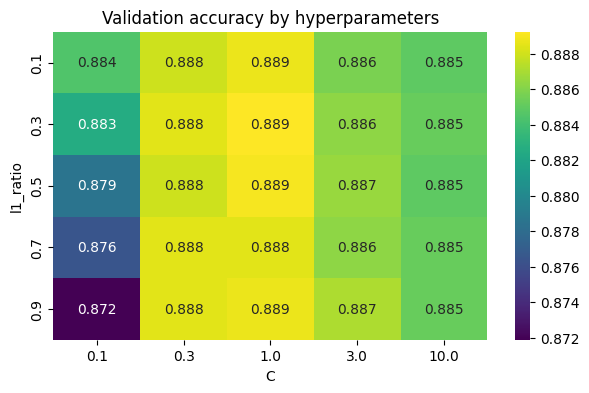

In [12]:
# Full Pipeline inside GridSearchCV: preprocessing is fit only on the data
# of each training fold (no data leakage).
pipe_en = Pipeline([('ct', preprocessor),
                    ('m', LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000, random_state=1))])

param_grid = {
    'm__C': [0.1, 0.3, 1, 3, 10],
    'm__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

grid = GridSearchCV(estimator=pipe_en,
                    param_grid=param_grid,
                    cv=cv,
                    scoring='accuracy',
                    n_jobs=-1,
                    return_train_score=True)

grid_result = grid.fit(Xtv, np.ravel(ytv))

# Train and validation scores of the BEST model (not the grid average)
i = grid_result.best_index_
res = grid_result.cv_results_
train_m, train_s = res['mean_train_score'][i], res['std_train_score'][i]
val_m, val_s = res['mean_test_score'][i], res['std_test_score'][i]
baseline_tv = 1 - np.ravel(ytv).mean()

print("Best model performance (accuracy)")
print("-"*65)
print("Best model: %f with hyperparameters %s" % (grid_result.best_score_, grid_result.best_params_))
print('Train mean(std): %.2f%% (%.2f%%)' % (100*train_m, 100*train_s))
print('Val   mean(std): %.2f%% (%.2f%%)' % (100*val_m, 100*val_s))
print('Train-Val gap: %.2f points -> %s' % (100*(train_m - val_m),
      'NOT overfit (< 3 points)' if (train_m - val_m) < 0.03 else 'possible overfitting (>= 3 points)'))
print('Baseline (always "No"): %.2f%% -> %s' % (100*baseline_tv,
      'NOT underfit' if val_m > baseline_tv else 'UNDERFIT'))

# Is the best value at the edge of the grid?
for p, vals in param_grid.items():
    b = grid_result.best_params_[p]
    if b in (min(vals), max(vals)):
        print(f"WARNING: {p}={b} is at the edge of the grid {vals}; consider widening it.")

# Heatmap of validation accuracy over the grid
table = (pd.DataFrame({'C': [d['m__C'] for d in res['params']],
                       'l1_ratio': [d['m__l1_ratio'] for d in res['params']],
                       'acc_val': res['mean_test_score']})
         .pivot(index='l1_ratio', columns='C', values='acc_val'))
plt.figure(figsize=(7, 4))
sns.heatmap(table, annot=True, fmt='.3f', cmap='viridis')
plt.title('Validation accuracy by hyperparameters')
plt.show()


Best combination: `C = 1`, `l1_ratio = 0.3`. Accuracy is 90.65% on Train and 88.92% on validation: a 1.7-point gap, so there is no relevant overfitting, and it beats the baseline (83.91%) by 5.0 percentage points.

## 10. Test-set evaluation

The test set is used once, with the model refit on Train + Validation.

In [13]:
# Performance report on Test

model_best = grid_result.best_estimator_      # Pipeline (preprocessing + model) already refit on Train+Val
y_test = np.ravel(ytestT)
y_pred_test = model_best.predict(Xtest)

print(classification_report(y_test, y_pred_test, target_names=['No', 'Yes']))

def wilson_ci(k, n, z=1.96):
    """Wilson confidence interval for a proportion k/n."""
    p = k / n
    d = 1 + z**2 / n
    c = p + z**2 / (2*n)
    a = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2))
    return (c - a)/d, (c + a)/d

n_test = len(y_test)
acc_test = metrics.accuracy_score(y_test, y_pred_test)
base_test = 1 - y_test.mean()
tp = int(((y_pred_test == 1) & (y_test == 1)).sum())
n_pos = int(y_test.sum())
lo, hi = wilson_ci(tp, n_pos)
lo_a, hi_a = wilson_ci(int(round(acc_test*n_test)), n_test)
print(f"Test accuracy: {acc_test:.3f} (95% CI {lo_a:.3f}-{hi_a:.3f}) vs. baseline {base_test:.3f} "
      f"-> difference of {100*(acc_test-base_test):.1f} percentage points")
print(f"Recall for 'Yes': {tp}/{n_pos} = {tp/n_pos:.3f} (95% CI {lo:.3f}-{hi:.3f}); with so few positive cases the interval is very wide.")


              precision    recall  f1-score   support

          No       0.89      0.95      0.92       185
         Yes       0.61      0.39      0.47        36

    accuracy                           0.86       221
   macro avg       0.75      0.67      0.70       221
weighted avg       0.84      0.86      0.85       221

Test accuracy: 0.860 (95% CI 0.808-0.899) vs. baseline 0.837 -> difference of 2.3 percentage points
Recall for 'Yes': 14/36 = 0.389 (95% CI 0.248-0.551); with so few positive cases the interval is very wide.


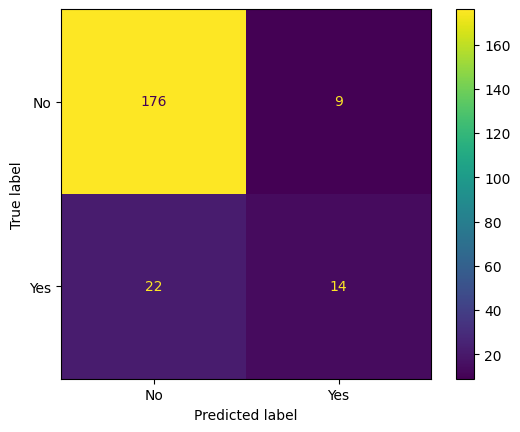

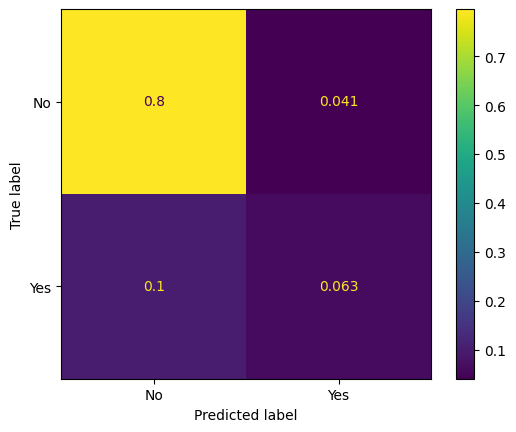

In [14]:
# Confusion matrix on Test
ConfusionMatrixDisplay.from_estimator(model_best, Xtest, ytestT, display_labels=['No','Yes'])
plt.show()
ConfusionMatrixDisplay.from_estimator(model_best, Xtest, ytestT, display_labels=['No','Yes'], normalize='all')
plt.show()


In [15]:
# Confusion matrix values
vn, fp, fn, vp = metrics.confusion_matrix(y_test, y_pred_test).ravel()
N = vn + fp + fn + vp
print(f"TN = {vn} ({vn/N:.3f})   FP = {fp} ({fp/N:.3f})   FN = {fn} ({fn/N:.3f})   TP = {vp} ({vp/N:.3f})")
print(f"Accuracy = (TN+TP)/N = {(vn+vp)/N:.3f}")
print(f"Recall for 'Yes' = TP/(TP+FN) = {vp/(vp+fn):.3f}  -> {100*fn/(vp+fn):.1f}% of the employees who left are missed")
print(f"Precision for 'Yes' = TP/(TP+FP) = {vp/(vp+fp):.3f}")


TN = 176 (0.796)   FP = 9 (0.041)   FN = 22 (0.100)   TP = 14 (0.063)
Accuracy = (TN+TP)/N = 0.860
Recall for 'Yes' = TP/(TP+FN) = 0.389  -> 61.1% of the employees who left are missed
Precision for 'Yes' = TP/(TP+FP) = 0.609


**Test results** (221 employees, 36 of whom left)

- Confusion matrix: TN = 176, FP = 9, FN = 22, TP = 14.
- Accuracy is 0.860 against a 0.837 baseline: a 2.3-percentage-point edge whose 95% confidence interval (0.81 to 0.90) includes the baseline. With this sample we cannot claim the model beats the naive one on accuracy.
- What matters is the "leaves" class: the model catches 14 of 36 leavers (recall 0.39, 95% CI 0.25 to 0.55) and misses 22 (61%). Of its 23 alerts, 14 are correct (precision 0.61).
- The dominant error is the false negative (22 versus 9), the opposite of what the cost of errors calls for.

## 11. Factors associated with attrition

In [16]:
# Feature importance (model coefficients)
feature_names = model_best.named_steps['ct'].get_feature_names_out()
coefs = model_best.named_steps['m'].coef_.ravel()
importance_df = (pd.DataFrame({'importance': coefs}, index=feature_names)
               .sort_values(by='importance', ascending=False))
display(importance_df)

print("Top 5 that INCREASE attrition probability:")
print(importance_df.head(5).round(3).to_string())
print("\nTop 5 that DECREASE it:")
print(importance_df.tail(5).iloc[::-1].round(3).to_string())

protected_in_model = [n for n in importance_df.index if any(p in n for p in ['Age', 'Gender', 'MaritalStatus'])]
print("\nSensitive variables present in this model:")
print(importance_df.loc[protected_in_model].round(3).to_string())


,importance
bin__OverTime,2.084316
nom__BusinessTravel_Travel_Frequently,1.634004
nom__MaritalStatus_Single,0.994959
nom__JobRole_Laboratory Technician,0.683032
nom__BusinessTravel_Travel_Rarely,0.602515
num__YearsAtCompany,0.546345
nom__EducationField_Technical Degree,0.526100
num__NumCompaniesWorked,0.507927
num__DistanceFromHome,0.419522
num__YearsSinceLastPromotion,0.330094


Top 5 that INCREASE attrition probability:
                                       importance
bin__OverTime                               2.084
nom__BusinessTravel_Travel_Frequently       1.634
nom__MaritalStatus_Single                   0.995
nom__JobRole_Laboratory Technician          0.683
nom__BusinessTravel_Travel_Rarely           0.603

Top 5 that DECREASE it:
                                importance
num__MonthlyIncome                  -0.563
nom__JobRole_Research Director      -0.555
ord__EnvironmentSatisfaction        -0.530
num__YearsInCurrentRole             -0.513
ord__JobInvolvement                 -0.468

Sensitive variables present in this model:
                            importance
nom__MaritalStatus_Single        0.995
bin__Gender                      0.302
nom__MaritalStatus_Married       0.177
num__Age                        -0.306


A positive coefficient raises the probability of leaving (in log-odds) and a negative one lowers it.

- **Raise risk:** working overtime (`OverTime`, 2.08), frequent business travel (1.63, versus no travel), being single (0.99, versus divorced) and being a Laboratory Technician (0.68). This is consistent with the observed rates in Train (32% attrition with overtime versus 10% without).
- **Lower risk:** higher monthly income (-0.56), being a Research Director (-0.56), higher environment satisfaction (-0.53) and more years in the current role (-0.51).

Four cautions when reading them:

1. They are associations, not causes, and the dataset is synthetic.
2. With correlated variables the coefficients are unstable: `MonthlyIncome` and `JobLevel` have a VIF near 11, and `YearsAtCompany` comes out positive (+0.55) while `YearsInCurrentRole` comes out negative. Observed rates are a safer guide than any single coefficient.
3. Numeric variables are standardized and dummies are not, so their magnitudes are not strictly comparable.
4. With `drop='first'`, each dummy is compared against the dropped category.

**Ethical flag:** `MaritalStatus_Single` is the third strongest factor, and Gender (+0.30) and Age (-0.31) also take part in the model. The next section measures what happens when they are removed.

## 12. Beyond accuracy: threshold, class_weight and sensitive attributes

So far accuracy was optimized, but the costliest error is the false negative. This section answers three questions:

1. What is gained by changing the decision threshold (instead of 0.5) or using `class_weight='balanced'`?
2. How much is lost by removing Age, Gender and MaritalStatus?
3. Does the model catch leavers equally well across groups (gender, marital status, age)?

Ground rules to avoid cheating: the threshold is chosen with out-of-fold predictions on Train + Validation using F2 (recall weighs twice as much as precision). The test set is not used to choose anything: it is reported as a descriptive evaluation.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

SENSITIVE = ['Age', 'Gender', 'MaritalStatus']
best_C  = grid_result.best_params_['m__C']
best_l1 = grid_result.best_params_['m__l1_ratio']
y_tv = np.ravel(ytv)
y_test = np.ravel(ytestT)

def make_ct(exclude=()):
    """Same preprocessing as section 7, optionally excluding columns."""
    blocks = [('num', numeric_pipeline, numeric_cols),
               ('ord', ordinal_pipeline, ordinal_cols),
               ('bin', binary_pipeline, binary_cols),
               ('nom', nominal_pipeline, nominal_cols)]
    out = []
    for name, pipe, cols in blocks:
        cols = [c for c in cols if c not in exclude]
        if cols:
            out.append((name, pipe, cols))
    return ColumnTransformer(out)

def make_pipe(exclude=(), class_weight=None):
    return Pipeline([('ct', make_ct(exclude)),
                     ('m', LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=best_l1, C=best_C,
                                              class_weight=class_weight, max_iter=5000, random_state=1))])

def threshold_f2(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    f2 = (5 * prec * rec) / (4 * prec + rec + 1e-12)
    return float(thr[np.argmax(f2)])

def compute_metrics(y, p, threshold):
    pred = (p >= threshold).astype(int)
    return {'threshold': round(threshold, 3),
            'accuracy': metrics.accuracy_score(y, pred),
            'precision': metrics.precision_score(y, pred, zero_division=0),
            'recall': metrics.recall_score(y, pred),
            'F1': metrics.f1_score(y, pred),
            'ROC-AUC': roc_auc_score(y, p),
            'PR-AUC': average_precision_score(y, p),
            'flagged': int(pred.sum())}

scenarios = {
    'A) Base, threshold 0.5':                         dict(exclude=(),         class_weight=None,       tune=False),
    'B) class_weight=balanced, threshold 0.5':        dict(exclude=(),         class_weight='balanced', tune=False),
    'C) Base, tuned threshold (F2)':             dict(exclude=(),         class_weight=None,       tune=True),
    'D) Without sensitive attributes, tuned threshold (F2)':   dict(exclude=SENSITIVE, class_weight=None,       tune=True),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
oof_probs, thresholds, oof_table, test_table = {}, {}, [], []

for name, cfg in scenarios.items():
    pipe = make_pipe(cfg['exclude'], cfg['class_weight'])
    p_oof = cross_val_predict(pipe, Xtv, y_tv, cv=skf, method='predict_proba')[:, 1]
    threshold = threshold_f2(y_tv, p_oof) if cfg['tune'] else 0.5
    oof_probs[name], thresholds[name] = p_oof, threshold
    oof_table.append({'scenario': name, **compute_metrics(y_tv, p_oof, threshold)})

    pipe.fit(Xtv, y_tv)
    p_test = pipe.predict_proba(Xtest)[:, 1]
    test_table.append({'scenario': name, **compute_metrics(y_test, p_test, threshold)})

oof_table = pd.DataFrame(oof_table).set_index('scenario')
test_table = pd.DataFrame(test_table).set_index('scenario')

print("Train+Val, out-of-fold predictions (the tuned threshold was chosen here, so this is somewhat optimistic):")
display(oof_table.round(3))
print(f"Test ({len(y_test)} employees, {int(y_test.sum())} who left). Descriptive only: not used to pick the threshold or the scenario:")
display(test_table.round(3))
print(f"Test baseline (accuracy, always 'No'): {1 - y_test.mean():.3f}")


Train+Val, out-of-fold predictions (the tuned threshold was chosen here, so this is somewhat optimistic):


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,flagged
scenario,,,,,,,,
"A) Base, threshold 0.5",0.500,0.889,0.750,0.463,0.572,0.845,0.643,124
"B) class_weight=balanced, threshold 0.5",0.500,0.774,0.392,0.731,0.510,0.834,0.612,375
"C) Base, tuned threshold (F2)",0.157,0.783,0.407,0.761,0.530,0.845,0.643,376
"D) Without sensitive attributes, tuned threshold (F2)",0.176,0.790,0.416,0.746,0.534,0.842,0.633,361


Test (221 employees, 36 who left). Descriptive only: not used to pick the threshold or the scenario:


,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,flagged
scenario,,,,,,,,
"A) Base, threshold 0.5",0.500,0.860,0.609,0.389,0.475,0.727,0.504,23
"B) class_weight=balanced, threshold 0.5",0.500,0.688,0.296,0.667,0.410,0.715,0.464,81
"C) Base, tuned threshold (F2)",0.157,0.688,0.291,0.639,0.400,0.727,0.504,79
"D) Without sensitive attributes, tuned threshold (F2)",0.176,0.710,0.311,0.639,0.418,0.719,0.493,74


Test baseline (accuracy, always 'No'): 0.837


In [18]:
# Performance by group (out-of-fold predictions on Train+Val): scenario C (with sensitive attributes) vs. D (without)
def group_table(name):
    d = Xtv.copy()
    d['y'] = y_tv
    d['pred'] = (oof_probs[name] >= thresholds[name]).astype(int)
    d['AgeGroup'] = pd.cut(d['Age'], [0, 29, 39, 100], labels=['<30', '30-39', '40+'])
    rows = []
    for var in ['Gender', 'MaritalStatus', 'AgeGroup']:
        for val, sub in d.groupby(var, observed=True):
            pos = sub['y'] == 1
            rows.append({'group': f'{var}={val}', 'n': len(sub), 'leavers': int(pos.sum()),
                          'flag_rate': sub['pred'].mean(),
                          'recall': sub.loc[pos, 'pred'].mean() if pos.sum() else np.nan})
    return pd.DataFrame(rows).set_index('group')

g_with = group_table('C) Base, tuned threshold (F2)')
g_without = group_table('D) Without sensitive attributes, tuned threshold (F2)')
comparison = g_with.join(g_without[['flag_rate', 'recall']], lsuffix='_with', rsuffix='_without')
print("With sensitive attributes (_with) vs. without them (_without):")
display(comparison.round(3))
print("Note: a very different recall across groups, or very different flag rates, is a sign of possible bias.")
print("Removing the sensitive attributes does not remove proxies (e.g. TotalWorkingYears or YearsAtCompany relative to age).")


With sensitive attributes (_with) vs. without them (_without):


,n,leavers,flag_rate_with,recall_with,flag_rate_without,recall_without
group,,,,,,
Gender=Female,508,76,0.276,0.776,0.289,0.763
Gender=Male,741,125,0.318,0.752,0.289,0.736
MaritalStatus=Divorced,289,30,0.208,0.800,0.215,0.767
MaritalStatus=Married,566,69,0.240,0.609,0.260,0.638
MaritalStatus=Single,394,102,0.457,0.853,0.386,0.814
AgeGroup=<30,276,77,0.486,0.857,0.438,0.831
AgeGroup=30-39,531,77,0.288,0.766,0.264,0.753
AgeGroup=40+,442,47,0.201,0.596,0.226,0.596


Note: a very different recall across groups, or very different flag rates, is a sign of possible bias.
Removing the sensitive attributes does not remove proxies (e.g. TotalWorkingYears or YearsAtCompany relative to age).


In [19]:
# Summary of results on Test
A, B, C, D = [test_table.loc[k] for k in test_table.index]
print("RECALL on Test (of those who left, how many are caught?)")
print(f"  A) threshold 0.5:                 {A['recall']:.2f}  (precision {A['precision']:.2f}, flagged {A['flagged']:.0f})")
print(f"  B) class_weight='balanced':    {B['recall']:.2f}  (precision {B['precision']:.2f}, flagged {B['flagged']:.0f})")
print(f"  C) tuned threshold (F2):     {C['recall']:.2f}  (precision {C['precision']:.2f}, flagged {C['flagged']:.0f})")
print(f"  D) no sensitive attrs + threshold:    {D['recall']:.2f}  (precision {D['precision']:.2f}, flagged {D['flagged']:.0f})")
print(f"\nCost of removing sensitive attributes (C -> D): ROC-AUC {C['ROC-AUC']:.3f} -> {D['ROC-AUC']:.3f}, "
      f"PR-AUC {C['PR-AUC']:.3f} -> {D['PR-AUC']:.3f}, recall {C['recall']:.2f} -> {D['recall']:.2f}")
print(f"\nNote: recall depends on the threshold; to compare models at different thresholds use ROC-AUC and PR-AUC.")
print(f"With only {int(y_test.sum())} positive cases in Test, differences of a few cases are not conclusive.")


RECALL on Test (of those who left, how many are caught?)
  A) threshold 0.5:                 0.39  (precision 0.61, flagged 23)
  B) class_weight='balanced':    0.67  (precision 0.30, flagged 81)
  C) tuned threshold (F2):     0.64  (precision 0.29, flagged 79)
  D) no sensitive attrs + threshold:    0.64  (precision 0.31, flagged 74)

Cost of removing sensitive attributes (C -> D): ROC-AUC 0.727 -> 0.719, PR-AUC 0.504 -> 0.493, recall 0.64 -> 0.64

Note: recall depends on the threshold; to compare models at different thresholds use ROC-AUC and PR-AUC.
With only 36 positive cases in Test, differences of a few cases are not conclusive.


**Test results** (36 employees who left; accuracy baseline 0.837)

| Scenario | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC | Flagged (of 221) |
|---|---|---|---|---|---|---|---|
| A) Threshold 0.5 | 0.860 | 0.61 | 0.39 | 0.47 | 0.727 | 0.504 | 23 |
| B) `class_weight='balanced'` | 0.688 | 0.30 | 0.67 | 0.41 | 0.715 | 0.464 | 81 |
| C) Tuned threshold (F2) | 0.688 | 0.29 | 0.64 | 0.40 | 0.727 | 0.504 | 79 |
| D) Without age, gender, marital status + tuned threshold | 0.710 | 0.31 | 0.64 | 0.42 | 0.719 | 0.493 | 74 |

**Threshold and class_weight.** Moving the threshold (C) catches about 2 of every 3 leavers, but it means flagging more than a third of the workforce (79 of 221) with roughly 70% false alarms, and accuracy falls below the baseline. It is the same model at a different operating point (the AUC is identical), not a free improvement. `class_weight` (B) reaches a similar point with a slightly lower ROC-AUC. Whether it is worth it depends on the cost of a retention intervention versus the cost of a resignation: that number lives with HR, not in the model.

**Sensitive attributes.** Removing age, gender and marital status (D) moves ROC-AUC from 0.845 to 0.842 in cross-validation and from 0.727 to 0.719 on the test set: no relevant performance loss, so there is no technical reason to keep them.

**Per-group audit** (out-of-fold predictions, model without sensitive attributes). Even without those variables, recall differs: 0.60 for employees aged 40+ versus 0.83 for those under 30, and 0.64 for married versus 0.81 for single employees; by gender the gap is small (0.76 and 0.74). Variables correlated with age, such as `TotalWorkingYears`, `YearsAtCompany` or `JobLevel`, may act as proxies. The 40+ group has only 47 positive cases, so the gap is uncertain, but large enough to audit before any use.

**On the test set.** Test ROC-AUC (0.73) is lower than in cross-validation (0.85). With 36 positives the standard error of the AUC is about 0.05, so the gap is roughly two standard errors: part may be noise and part cross-validation optimism (hyperparameters were chosen on the same data). Cross-validation, with 201 positives, is the more stable estimate; both should be reported.

## 13. Conclusions

1. In cross-validation the logistic models beat the baseline by about 5 percentage points of accuracy (0.889 versus 0.839), but on the test set the edge is only 2.3 points and is not statistically distinguishable.
2. Recall for employees who leave is low at the default threshold (0.39). Raising it to about 0.64 costs a precision of ~0.30 and flagging a third of the workforce.
3. Age, gender and marital status add no relevant discriminative power (ROC-AUC 0.845 to 0.842) and should be excluded. Even so, recall differs across age and marital-status groups.
4. Test-set results (36 positives) are noisy; cross-validation is the more stable estimate.

**Responsible use.** Alerts should reach HR only, as a prompt for a conversation, never as an automatic decision about a person or as a justification for a negative action. The model reflects historical patterns and knows nothing about each employee's individual situation; it should be audited by group before any use, and ideally employees are told that this kind of analysis is done.

**Limitations and next steps**

- Few positives in the test set: repeated or nested cross-validation would give tighter estimates.
- Try tree-based models and calibrate the probabilities; set the threshold from the real cost of an intervention versus a resignation.
- Investigate and mitigate the recall gap across groups (proxy variables).
- Other approaches the same data supports: employee segmentation with clustering; regression to predict time to the next promotion; and survival analysis, which estimates how long an employee stays and treats those still at the company as censored observations rather than as "will not leave".

---

**Author:** Ricardo Galván Páez · [GitHub](https://github.com/RicardoGalvanP) · [LinkedIn](https://www.linkedin.com/in/ricardo-galvan-paez)

**AI assistance:** Anthropic. (2026). *Claude (claude-sonnet-4-6)*. Used to explore hyperparameters and review transformations; the results and their interpretation were verified by the author.